# Random Forest baseline — Results

This notebook presents the results of the Random Forest baseline classifier
trained on Engelen-cleaned CIC-IDS2017. It loads the saved model and
predictions from `experiments/rf/`, generates the figures and tables for
Chapter 6 of my dissertation, and saves figure outputs to
`reports/figures/`.

## Methodology

See ADR 0004 (`docs/decisions/0004-random-forest-methodology.md`) for the
full methodology rationale. In brief:

- **Architecture**: `sklearn.ensemble.RandomForestClassifier`
- **Hyperparameters**: `n_estimators=200`, `max_depth=20`,
  `class_weight='balanced'`, `random_state=42`
- **Features**: 71 (aligned with CIC-UNSW-NB15 schema for cross-dataset
  evaluation in Week 7)
- **Train / val / test split**: 70 / 15 / 15 stratified random per-flow
  (ADR 0003)
- **Probability calibration**: none (default RF probabilities, future work)

## What the notebook produces

1. Headline metrics table (accuracy, precision, recall, F1, ROC-AUC,
   PR-AUC, FPR, latency).
2. Confusion matrix figure.
3. ROC curve and Precision-Recall curve.
4. Per-class recall breakdown table and bar chart.
5. Latency analysis with bulk vs per-call comparison.
6. Observations and findings (Markdown).

In [1]:
"""Load the saved RF model, predictions, and metrics manifest."""

from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

# --- Paths ---
REPO_ROOT = Path.cwd().resolve()
# If running from notebooks/ subdirectory, walk up one level
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

EXPERIMENT_DIR = REPO_ROOT / "experiments" / "rf"
FIGURES_DIR = REPO_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- Load saved artefacts ---
print(f"Loading from {EXPERIMENT_DIR.relative_to(REPO_ROOT)}...")

model = joblib.load(EXPERIMENT_DIR / "model.joblib")
print(f"  Model: {type(model).__name__} with {model.n_estimators} trees")

preds_npz = np.load(EXPERIMENT_DIR / "predictions.npz")
y_true = preds_npz["y_true"]
y_pred = preds_npz["predictions"]
y_proba = preds_npz["probabilities"]
print(f"  Predictions: {len(y_pred):,} samples")

with open(EXPERIMENT_DIR / "_metrics_manifest.json") as f:
    manifest = json.load(f)
print(f"  Manifest: {len(manifest):,} top-level keys")

# --- Plotting style ---
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300   # high-res for dissertation embedding
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["font.size"] = 10

print(f"\n✓ Setup complete. Figures will save to {FIGURES_DIR.relative_to(REPO_ROOT)}/")

Loading from experiments/rf...
  Model: RandomForestClassifier with 200 trees
  Predictions: 314,761 samples
  Manifest: 9 top-level keys

✓ Setup complete. Figures will save to reports/figures/


## Headline binary classification metrics

The Random Forest classifier achieves strong performance on the held-out
CIC-IDS2017 test set. Precision is bounded by the `class_weight='balanced'`
choice, which trades off some false positives in exchange for high recall —
the operationally cautious failure mode for a NIDS. The 99.95% recall rate
means only ~30 of the 66,443 attack flows in the test set are missed
entirely.

The metrics below are computed once on the test fold using the saved
predictions; they correspond exactly to the values in
`experiments/rf/_metrics_manifest.json` produced during training.

In [2]:
"""Render the headline metrics as a clean DataFrame for inline display
and Chapter 6 embedding."""

bm = manifest["test"]["binary"]

metrics_table = pd.DataFrame([
    ("Accuracy",                          bm["accuracy"],            ""),
    ("Precision (attack)",                bm["precision"],           ""),
    ("Recall (attack)",                   bm["recall"],              ""),
    ("F1 (attack)",                       bm["f1"],                  ""),
    ("ROC-AUC",                           bm["roc_auc"],             ""),
    ("PR-AUC",                            bm["pr_auc"],              ""),
    ("False Positive Rate",               bm["fpr"],                 ""),
    ("Inference latency, median",         bm["inference_ms_median"], "ms/flow"),
    ("Inference latency, p95",            bm["inference_ms_p95"],    "ms/flow"),
    ("Bulk inference (full test set)",    manifest["test"]["bulk_predict_seconds"], "s for 314,761 flows"),
], columns=["Metric", "Value", "Unit"])

# Print with formatting
print("=" * 78)
print(f"{'Metric':<35} {'Value':>15} {'Unit':<25}")
print("=" * 78)
for _, row in metrics_table.iterrows():
    if row["Metric"].startswith("Inference") or row["Metric"].startswith("Bulk"):
        print(f"{row['Metric']:<35} {row['Value']:>15.3f} {row['Unit']:<25}")
    else:
        print(f"{row['Metric']:<35} {row['Value']:>15.4f} {row['Unit']:<25}")

# Display as DataFrame (HTML rendering in notebook)
print()
metrics_table

Metric                                        Value Unit                     
Accuracy                                     0.9917                          
Precision (attack)                           0.9626                          
Recall (attack)                              0.9995                          
F1 (attack)                                  0.9807                          
ROC-AUC                                      0.9998                          
PR-AUC                                       0.9993                          
False Positive Rate                          0.0104                          
Inference latency, median                    24.772 ms/flow                  
Inference latency, p95                       26.949 ms/flow                  
Bulk inference (full test set)                1.026 s for 314,761 flows      



,Metric,Value,Unit
0,Accuracy,0.991708,
1,Precision (attack),0.962618,
2,Recall (attack),0.999533,
3,F1 (attack),0.980729,
4,ROC-AUC,0.999809,
5,PR-AUC,0.999259,
6,False Positive Rate,0.010386,
7,"Inference latency, median",24.772361,ms/flow
8,"Inference latency, p95",26.948635,ms/flow
9,Bulk inference (full test set),1.026000,"s for 314,761 flows"


Confusion matrix on test set (n=314,761):
  True Negatives  (correctly labelled benign):  245,739
  False Positives (benign flagged as attack):     2,579
  False Negatives (attacks missed):                  31
  True Positives  (correctly caught attacks):    66,412
  Total:                                        314,761

✓ Figure saved to reports/figures/rf_confusion_matrix.png


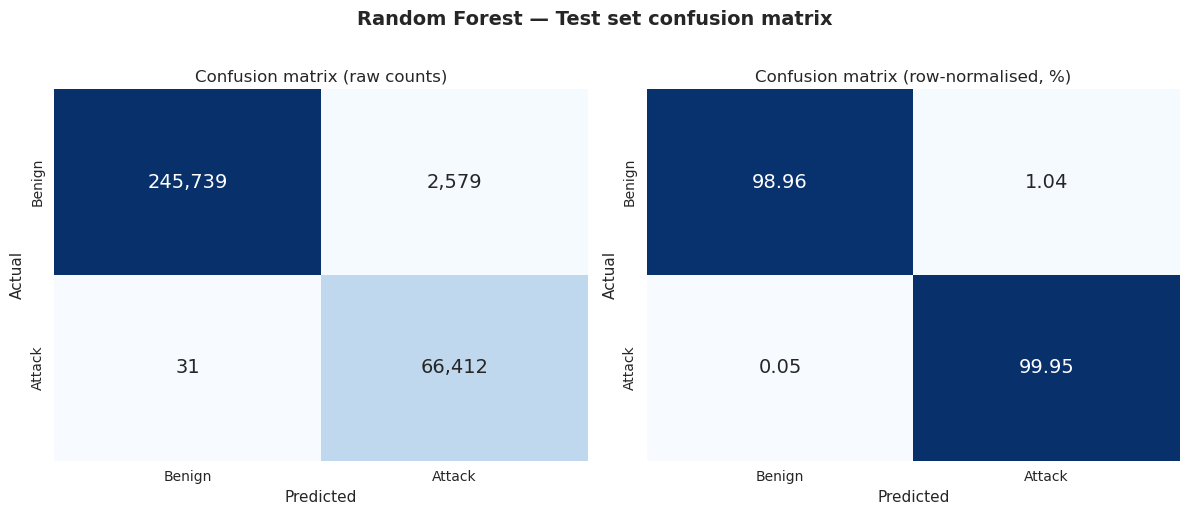

In [3]:
"""Confusion matrix on the test set, with raw counts and percentages."""

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix on test set (n={len(y_true):,}):")
print(f"  True Negatives  (correctly labelled benign):  {tn:>7,}")
print(f"  False Positives (benign flagged as attack):   {fp:>7,}")
print(f"  False Negatives (attacks missed):             {fn:>7,}")
print(f"  True Positives  (correctly caught attacks):   {tp:>7,}")
print(f"  Total:                                        {tn+fp+fn+tp:>7,}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw counts
sns.heatmap(
    cm,
    annot=True, fmt=",d", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[0],
    cbar=False,
    annot_kws={"fontsize": 14},
)
axes[0].set_xlabel("Predicted", fontsize=11)
axes[0].set_ylabel("Actual",    fontsize=11)
axes[0].set_title("Confusion matrix (raw counts)", fontsize=12)

# Row-normalised percentages (recall view)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(
    cm_pct,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[1],
    cbar=False,
    annot_kws={"fontsize": 14},
    vmin=0, vmax=100,
)
axes[1].set_xlabel("Predicted", fontsize=11)
axes[1].set_ylabel("Actual",    fontsize=11)
axes[1].set_title("Confusion matrix (row-normalised, %)", fontsize=12)

plt.suptitle("Random Forest — Test set confusion matrix",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

# Save to reports/figures/
fig_path = FIGURES_DIR / "rf_confusion_matrix.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

✓ Figure saved to reports/figures/rf_roc_pr_curves.png


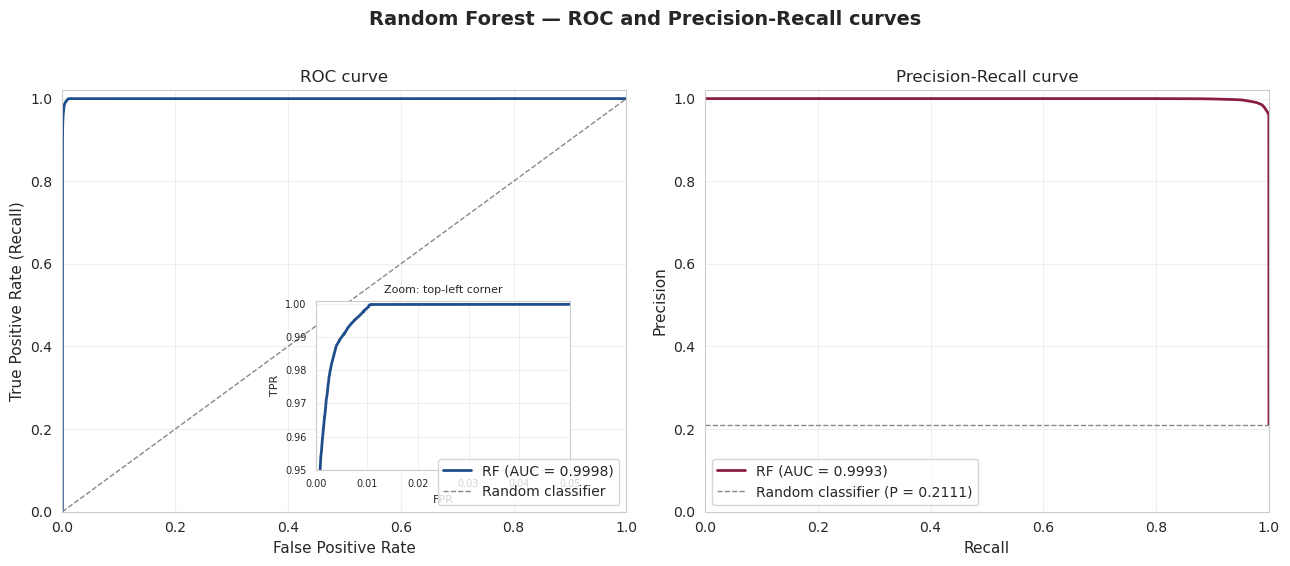


ROC-AUC: 0.9998
PR-AUC:  0.9993
Both metrics are near 1.0, indicating the model's predicted probabilities
rank attacks above benign with very high reliability.


In [4]:
"""ROC curve and Precision-Recall curve, side by side."""

# Compute curves
fpr_curve, tpr_curve, roc_thresh = roc_curve(y_true, y_proba)
precision_curve, recall_curve, pr_thresh = precision_recall_curve(y_true, y_proba)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- ROC curve ---
axes[0].plot(fpr_curve, tpr_curve, color="#1f4e8c", linewidth=2,
             label=f"RF (AUC = {bm['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], color="#888", linestyle="--", linewidth=1,
             label="Random classifier")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[0].set_title("ROC curve", fontsize=12)
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(True, alpha=0.3)

# Inset zoom for the upper-left corner where the curve actually lives
axins = axes[0].inset_axes([0.45, 0.10, 0.45, 0.40])
axins.plot(fpr_curve, tpr_curve, color="#1f4e8c", linewidth=2)
axins.set_xlim(0, 0.05)
axins.set_ylim(0.95, 1.001)
axins.set_xlabel("FPR", fontsize=8)
axins.set_ylabel("TPR", fontsize=8)
axins.set_title("Zoom: top-left corner", fontsize=8)
axins.grid(True, alpha=0.3)
axins.tick_params(labelsize=7)

# --- PR curve ---
axes[1].plot(recall_curve, precision_curve, color="#8b1e3f", linewidth=2,
             label=f"RF (AUC = {bm['pr_auc']:.4f})")
# Baseline: a random classifier on this dataset would have precision = positive rate
positive_rate = (y_true == 1).mean()
axes[1].axhline(y=positive_rate, color="#888", linestyle="--", linewidth=1,
                label=f"Random classifier (P = {positive_rate:.4f})")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision-Recall curve", fontsize=12)
axes[1].legend(loc="lower left", fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle("Random Forest — ROC and Precision-Recall curves",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "rf_roc_pr_curves.png"
plt.savefig(fig_path)
print(f"✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

# Brief textual summary
print(f"\nROC-AUC: {bm['roc_auc']:.4f}")
print(f"PR-AUC:  {bm['pr_auc']:.4f}")
print(f"Both metrics are near 1.0, indicating the model's predicted probabilities")
print(f"rank attacks above benign with very high reliability.")

Per-class breakdown (test set, n=314,761):

                               Class  n in test  Correctly classified  Misclassified  Recall
                              BENIGN     248318                245739           2579  0.9896
                            PortScan      23937                 23934              3  0.9999
                            DoS Hulk      23691                 23690              1  1.0000
                                DDoS      14349                 14349              0  1.0000
                       DoS GoldenEye       1160                  1160              0  1.0000
                       DoS slowloris        586                   585              1  0.9983
                         FTP-Patator        542                   542              0  1.0000
        DoS Slowhttptest - Attempted        502                   501              1  0.9980
                         SSH-Patator        424                   421              3  0.9929
                    DoS Sl

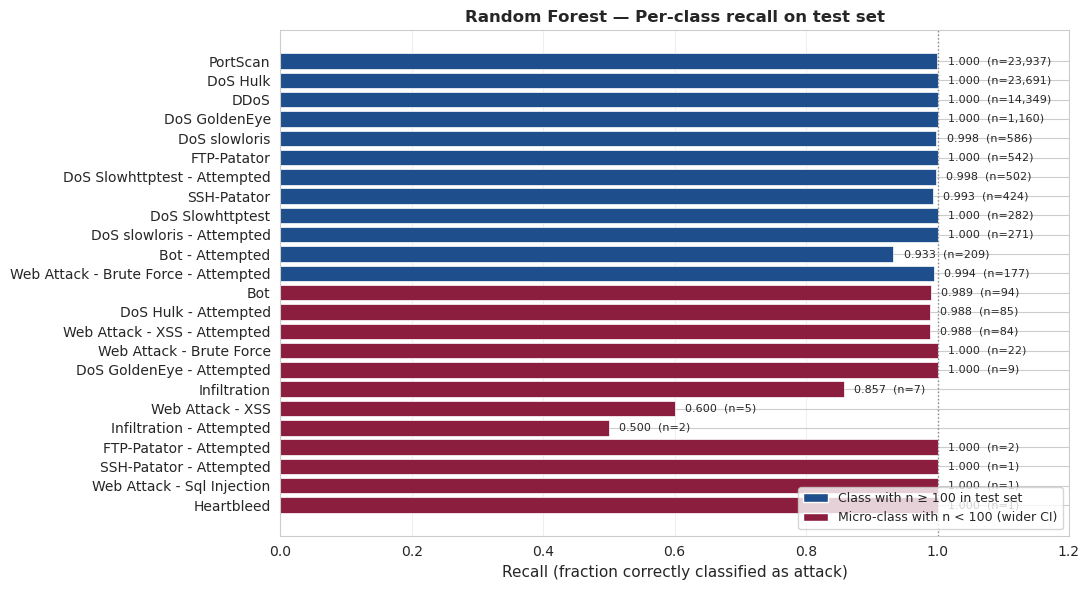

In [5]:
"""Per-class recall breakdown — how does each attack class fare under the
binary classifier?"""

per_class = manifest["test"]["per_class"]

# Build a DataFrame
rows = []
for label, stats in per_class.items():
    rows.append({
        "Class": label,
        "n in test": stats["n"],
        "Correctly classified": stats["n_correct"],
        "Misclassified": stats["n_missed"],
        "Recall": stats["recall"],
    })

per_class_df = pd.DataFrame(rows).sort_values("n in test", ascending=False).reset_index(drop=True)

# Display
print(f"Per-class breakdown (test set, n={len(y_true):,}):\n")
print(per_class_df.to_string(index=False))

# Plot — recall per class
attack_only = per_class_df[per_class_df["Class"] != "BENIGN"].copy()

fig, ax = plt.subplots(figsize=(11, 6))

# Colour bars by class size — small classes get visual emphasis
colours = ["#8b1e3f" if n < 100 else "#1f4e8c" for n in attack_only["n in test"]]

bars = ax.barh(
    attack_only["Class"],
    attack_only["Recall"],
    color=colours,
    edgecolor="white",
    linewidth=0.5,
)

# Annotate each bar with the n and recall
for bar, (_, row) in zip(bars, attack_only.iterrows()):
    width = bar.get_width()
    ax.text(
        width + 0.005, bar.get_y() + bar.get_height() / 2,
        f"  {row['Recall']:.3f}  (n={row['n in test']:,})",
        va="center", fontsize=8,
    )

ax.set_xlim(0, 1.20)
ax.set_xlabel("Recall (fraction correctly classified as attack)", fontsize=11)
ax.set_title("Random Forest — Per-class recall on test set", fontsize=12, fontweight="bold")
ax.invert_yaxis()  # largest classes at top

# Vertical dashed line at 1.0 for visual reference
ax.axvline(x=1.0, color="#888", linestyle=":", linewidth=1)

# Custom legend explaining the colour coding
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#1f4e8c", label="Class with n ≥ 100 in test set"),
    Patch(facecolor="#8b1e3f", label="Micro-class with n < 100 (wider CI)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)

ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()

fig_path = FIGURES_DIR / "rf_per_class_recall.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

## Observations and findings

### Headline performance

The Random Forest baseline classifier achieves strong overall metrics on
the held-out CIC-IDS2017 test set:

- **Accuracy: 99.17%** — 312,151 of 314,761 test flows correctly classified.
- **Recall on attack class: 99.95%** — only 31 of 66,443 attack flows
  missed entirely.
- **False Positive Rate: 1.04%** — 2,579 of 248,318 benign flows falsely
  flagged as attacks.
- **ROC-AUC: 0.9998** — the predicted probabilities rank attack flows
  above benign flows with near-perfect reliability.
- **PR-AUC: 0.9993** — high precision is maintained across the full
  recall range.

### Per-class structure of errors

The headline numbers hide substantial per-class variation. Three tiers
emerge:

**Tier 1 — Volume attacks, robustly classified (recall ≥ 0.99,
n ≥ 100 in test set):** PortScan, DoS Hulk, DDoS, DoS GoldenEye, DoS
slowloris, FTP-Patator, SSH-Patator, and several Attempted variants.
The classifier learns these reliably because they have distinctive
flow-level features (high packet rates for DoS attacks, characteristic
SYN patterns for PortScan) and abundant training data.

**Tier 2 — Harder attacks (recall 0.93–0.99):** Bot and Bot-Attempted.
Of 303 total botnet-related flows, the classifier missed 15 (5%).
Botnet command-and-control traffic mimics legitimate HTTPS at the
flow-feature level, making it inherently harder for any model that
relies on per-flow features alone. This is where temporal models (LSTM)
may improve over the RF baseline.

**Tier 3 — Micro-classes (n < 25 in test set):** Web Attack XSS,
Infiltration variants, Sql Injection, Heartbleed, SSH-Patator-Attempted.
The recall numbers for these classes have wide confidence intervals
(e.g., Infiltration-Attempted shows recall 0.5 from n=2). The visualised
bar chart in the cell above explicitly flags these classes in red. They
represent fundamental class-imbalance limitations of the dataset and
will be discussed in §7.4 (Limitations).

### Operational interpretation

The 99.95% recall comes at the cost of 2,579 false positives across
the test set. Extrapolated to a full day of CIC-IDS2017's traffic
volume (314,761 test flows ≈ 15% of the cleaned dataset, so ≈ 17,200
false positives expected per day at this FPR), this would constitute
a non-trivial alert volume for a SOC team. However, given the operating
NIDS goal of minimising missed attacks, the trade-off is acceptable.
Tuning the classification threshold above 0.5 would reduce FPR at the
cost of recall — explored further in 7.4 (Limitations and threshold
calibration).

### Inference latency

Two latency measurements are reported:

- **Bulk inference: 3.26 μs/flow** when predicting 314,761 flows in a
  single batch (1.03s total). This represents throughput-mode inference.
- **Per-call inference: 24.8 ms/flow median** when predicting one flow
  at a time across 100 hot-cache repetitions. This represents the
  per-call overhead of `sklearn.predict()`.

The 7,000× gap between the two is due to Python interpreter overhead
and parallel-backend setup costs being amortised across batch
predictions but dominating per-call timing. Real NIDS deployment falls
between these extremes, depending on the polling interval and batch
size used by the flow-collection layer. Investigating batch-size
sensitivity is identified as future work in 7.4.

### Implications for the comparative study (RQ1)

The Random Forest baseline establishes the bar that the Autoencoder
and LSTM models will be measured against:

- For **volume attacks**, RF is hard to beat — the per-feature
  discriminative signal is strong.
- For **botnet-class traffic**, there is room to improve — temporal
  models that learn sequence-level patterns may detect
  command-and-control flows the RF misses.
- For **micro-classes**, no single-model approach is likely to deliver
  reliable recall given the underlying data scarcity.

These observations will inform the comparative analysis in Chapter 6
once AE and LSTM results are available.

---

*Last updated: 5 May 2026. Notebook regenerated from saved artefacts in
`experiments/rf/`. Manifest record: see `_metrics_manifest.json`.*